# OS Tutor — QLoRA Fine-Tuning v2 (publication-grade pipeline)

**Model:** Qwen2.5-1.5B-Instruct · **Method:** QLoRA (Unsloth + TRL) · **GPU:** Colab T4 (free tier is enough)

> **Runtime → Change runtime type → T4 GPU**, then *Run all*. Everything is checkpointed to Google Drive, so a disconnect only costs the seed that was running.

### What changed vs. `qwen_os_tutor_finetune.ipynb` (v1) and why
| # | v1 problem (found in the saved `trainer_state.json`) | v2 fix |
|---|---|---|
| 1 | 58 of 60 validation rows shared their textbook passage with a training row (only 124 unique passages for 702 rows) → validation loss measured memorisation, not generalisation | **Group-aware split by passage**; passages never cross train / val / test |
| 2 | Validation set had 0 `out_of_context` rows and 1–3 rows in several categories | Stratified val **and** a separate untouched **test** set |
| 3 | Final adapter = step 150 although step 100 had the best val loss (0.496 vs 0.515) | **Early stopping** + best checkpoint restored; eval 3×/epoch |
| 4 | Loss over the whole sequence (system prompt + passage + answer) | **Answer-only loss** (`train_on_responses_only`), switchable for an ablation |
| 5 | Minority categories duplicated ×3 (memorisation) | Off by default, still available as an ablation flag |
| 6 | ~half of the `recall` answers are *not supported by their passage*, which contradicts the system prompt | **Groundedness audit** + optional filter |
| 7 | Only a 2-prompt smoke test, no metrics | Held-out **test** metrics: EM, token-F1, ROUGE-L, number recall, refusal P/R/F1, answer-NLL |
| 8 | No baseline | **Un-tuned base model** evaluated on the same test set |
| 9 | One run | **3 seeds**, mean ± std, bootstrap CIs, paired significance test |
| 10 | Deployed prompt ≠ training prompt (`rag/qwen_chain.py`) | Test set scored under **both** prompts |
| 11 | No logs saved, nothing reproducible | All logs / predictions / configs / versions saved; paper figures generated |

**Run order:** just run top to bottom. To run an ablation, change `EXPERIMENT` + one flag in the *Config* cell and run again; the last section compares all experiments.

## 1 · Setup

In [1]:
# Installs Unsloth + datasets (~2-3 min on a fresh runtime). No restart needed on a FRESH runtime;
# if you already imported torch/transformers in this runtime, do Runtime > Restart session first.
!pip install -q --upgrade unsloth datasets

In [2]:
import unsloth  # noqa: F401  -- must be imported BEFORE transformers / trl / peft
from unsloth import FastLanguageModel
from unsloth.chat_templates import train_on_responses_only

import os, sys, gc, json, re, time, math, random, shutil, inspect, platform, warnings, collections
from importlib import metadata
import numpy as np, pandas as pd, torch
import torch.nn.functional as F
from datasets import Dataset
from transformers import AutoTokenizer, EarlyStoppingCallback, set_seed
from trl import SFTTrainer, SFTConfig

warnings.filterwarnings('ignore', category=FutureWarning)
assert torch.cuda.is_available(), 'No GPU found. Runtime > Change runtime type > T4 GPU'

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s); set_seed(s)

def pkg(n):
    try: return metadata.version(n)
    except Exception: return 'n/a'

ENV = {'python': sys.version.split()[0], 'platform': platform.platform(),
       'gpu': torch.cuda.get_device_name(0), 'vram_gb': round(torch.cuda.get_device_properties(0).total_memory/1e9, 1),
       **{p: pkg(p) for p in ['torch','transformers','trl','peft','unsloth','datasets','bitsandbytes','accelerate']}}
for k, v in ENV.items(): print(f'{k:13s}: {v}')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
python       : 3.13.16
platform     : Linux-6.6.159+-x86_64-with-glibc2.39
gpu          : Tesla T4
vram_gb      : 15.6
torch        : 2.11.0+cu130
transformers : 5.17.0
trl          : 1.15.0
peft         : 0.21.2
unsloth      : 2026.10.10
datasets     : 4.8.5
bitsandbytes : 0.50.2
accelerate   : 1.15.0


In [6]:
# ─────────────────────────── CONFIG (edit here) ───────────────────────────
IN_COLAB = 'google.colab' in sys.modules

CFG = dict(
    EXPERIMENT   = 'main',            # name of this run; ablations get their own folder
    MODEL_ID     = 'Qwen/Qwen2.5-1.5B-Instruct',
    MAX_SEQ_LEN  = 1024,
    # LoRA
    LORA_R = 16, LORA_ALPHA = 32, LORA_DROPOUT = 0.05,
    TARGET_MODULES = ['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj'],
    # optimisation
    EPOCHS = 3, BATCH_SIZE = 2, GRAD_ACCUM = 8, LR = 2e-4, WEIGHT_DECAY = 0.01, WARMUP_RATIO = 0.05,
    EVALS_PER_EPOCH = 3, EARLY_STOP_PATIENCE = 3,
    SEEDS = [42, 43, 44],             # >=3 seeds for mean +- std. Use [42] for a quick smoke run.
    # data
    DATA_FILES = {'train': 'dataset_v2_train.csv', 'val': 'dataset_v2_val.csv'},
    SPLIT_SEED = 42, VAL_FRAC = 0.12, TEST_FRAC = 0.12,
    # ablation switches
    TRAIN_ON_RESPONSES_ONLY = True,   # answer-only loss
    OVERSAMPLE_CATS   = ['comparative','analytical','negative_edge_case','applied_conceptual'],
    OVERSAMPLE_FACTOR = 1,            # 1 = off (v1 used 3). Duplicates rows -> memorisation risk.
    FILTER_UNGROUNDED = False,        # drop rows whose answer is mostly NOT supported by the passage
    FILTER_CATS       = ['recall'],
    GROUND_THRESH     = 0.30,
    # evaluation
    GEN_MAX_NEW_TOKENS = 400, GEN_BATCH = 8,
    EVAL_DEPLOY_PROMPT = True,        # also score the prompt used in rag/qwen_chain.py (train/serve mismatch)
    KEEP_CHECKPOINTS   = False,
    USE_DRIVE = True,
)

DEPLOY_SYSTEM = (
    "You are a concise Operating Systems tutor based on the Galvin textbook. "
    "Answer DIRECTLY and SPECIFICALLY. Do NOT ramble, speculate, or go off-topic. "
    "If textbook passages are provided, base your answer strictly on them. "
    "Keep answers short: 2-5 sentences maximum unless a step-by-step solution is needed. "
    "For numerical problems, show only the key steps and the final answer. "
    "NEVER invent figures, page numbers, or facts not in the context. "
    "NEVER ask follow-up questions back to the student."
)

if IN_COLAB and CFG['USE_DRIVE']:
    from google.colab import drive
    drive.mount('/content/drive')
    WORK_DIR = '/content/drive/MyDrive/os_tutor_ft2'
else:
    WORK_DIR = './ft2_runs'
RUN_DIR = os.path.join(WORK_DIR, CFG['EXPERIMENT'])
os.makedirs(os.path.join(RUN_DIR, 'figures'), exist_ok=True)
json.dump(CFG, open(os.path.join(RUN_DIR, 'config.json'), 'w'), indent=2)
print('Run directory:', os.path.abspath(RUN_DIR))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Run directory: /content/drive/MyDrive/os_tutor_ft2/main


## 2 · Data: load, audit, split

The audit below is not decoration — it is what a reviewer will ask for. Two things matter most:
**(a)** does a row's answer actually come from its passage (the system prompt says it must), and
**(b)** do validation/test passages also appear in training (leakage)?

In [7]:
def find_file(name):
    for d in ['/content', WORK_DIR, '.']:
        p = os.path.join(d, name)
        if os.path.exists(p): return p
    return None

paths = {k: find_file(v) for k, v in CFG['DATA_FILES'].items()}
if any(p is None for p in paths.values()):
    if IN_COLAB:
        from google.colab import files
        print('Upload', list(CFG['DATA_FILES'].values()))
        files.upload()
        paths = {k: v for k, v in CFG['DATA_FILES'].items()}
    else:
        raise FileNotFoundError(f'Missing data files: {paths}')

raw = pd.concat([pd.read_csv(p).assign(orig_split=k) for k, p in paths.items()], ignore_index=True)
need = {'category','difficulty','system','prompt','completion'}
assert need <= set(raw.columns), f'missing columns: {need - set(raw.columns)}'
raw = raw.dropna(subset=['system','prompt','completion']).reset_index(drop=True)

CTX_RE = re.compile(r'Textbook passages:\s*(.*?)\s*Question:\s*(.*)\Z', re.S)
def parse_prompt(p):
    m = CTX_RE.search(p)
    return (m.group(1).strip(), m.group(2).strip()) if m else ('', p.strip())
parsed = [parse_prompt(p) for p in raw.prompt]
raw['context']  = [a for a, _ in parsed]
raw['question'] = [b for _, b in parsed]

WORD4 = re.compile(r'[a-z]{4,}')
def support(answer, context):
    # fraction of the answer's content words (>=4 letters) that occur in the passage -- lexical groundedness proxy
    a = set(WORD4.findall(answer.lower())); c = set(WORD4.findall(context.lower()))
    return len(a & c) / max(1, len(a))
raw['support'] = [support(a, c) for a, c in zip(raw.completion, raw.context)]
raw['is_ooc']  = raw.completion.str.strip().eq('OUT_OF_CONTEXT')
# split-group key: the passage, except for refusal rows where the (off-topic) QUESTION is what must not leak
raw['gkey'] = np.where(raw.category == 'out_of_context', 'OOC::' + raw.question, raw.context)

SYSTEM_PROMPT = raw.system.mode()[0]

# ── Audit ────────────────────────────────────────────────────────────────
tr_ctx = set(raw.loc[raw.orig_split=='train','context'])
va = raw[raw.orig_split=='val']
audit = {
    'rows': len(raw), 'unique_passages': int(raw.context.nunique()),
    'unparsed_prompts': int((raw.context=='').sum()),
    'duplicate_rows': int(raw.duplicated(['system','prompt','completion']).sum()),
    'distinct_system_prompts': int(raw.system.nunique()),
    'original_val_rows_sharing_passage_with_train': int(va.context.isin(tr_ctx).sum()),
    'original_val_rows': int(len(va)),
    'ooc_rows': int((raw.category=='out_of_context').sum()),
    'ooc_unique_questions': int(raw.loc[raw.category=='out_of_context','question'].nunique()),
    'ooc_rows_wrong_category': int((raw.is_ooc & (raw.category!='out_of_context')).sum()),
}
print(json.dumps(audit, indent=2))
print('\nGroundedness proxy (share of answer words found in the passage), by category:')
g = raw.groupby('category').support.agg(['count','mean','median']).round(2)
g['ungrounded(<%.2f)' % CFG['GROUND_THRESH']] = raw.assign(u=raw.support < CFG['GROUND_THRESH']).groupby('category').u.sum()
print(g.to_string())
json.dump(audit, open(os.path.join(RUN_DIR,'data_audit.json'),'w'), indent=2)

{
  "rows": 762,
  "unique_passages": 126,
  "unparsed_prompts": 0,
  "duplicate_rows": 0,
  "distinct_system_prompts": 1,
  "original_val_rows_sharing_passage_with_train": 58,
  "original_val_rows": 60,
  "ooc_rows": 40,
  "ooc_unique_questions": 14,
  "ooc_rows_wrong_category": 0
}

Groundedness proxy (share of answer words found in the passage), by category:
                    count  mean  median  ungrounded(<0.30)
category                                                  
analytical             11  0.11    0.11                 11
applied_conceptual     18  0.09    0.09                 18
applied_numerical     380  0.44    0.43                135
comparative            12  0.22    0.21                 10
negative_edge_case     14  0.12    0.12                 14
out_of_context         40  0.00    0.00                 40
recall                287  0.55    0.36                133


In [8]:
def group_stratified_split(df, val_frac, test_frac, seed):
    # Assign whole passages (groups) to train/val/test so no passage is shared, while keeping the
    # per-category proportions close to the targets (greedy on the relative deficit).
    rng = np.random.RandomState(seed)
    cats = sorted(df.category.unique())
    tot = df.category.value_counts().to_dict()
    frac = {'val': val_frac, 'test': test_frac, 'train': 1 - val_frac - test_frac}
    target = {s: {c: tot[c]*frac[s] for c in cats} for s in frac}
    cur = {s: {c: 0 for c in cats} for s in frac}
    items = list(df.groupby('gkey').indices.items())
    rng.shuffle(items); items.sort(key=lambda kv: -len(kv[1]))     # big groups first, random among ties
    assign = np.empty(len(df), dtype=object)
    for _, idx in items:
        cnt = df.category.iloc[idx].value_counts()
        best, best_s = None, -1e18
        for s in ('val', 'test', 'train'):
            score = sum(n * (target[s][c] - cur[s][c]) / max(target[s][c], 1e-9) for c, n in cnt.items())
            if score > best_s: best, best_s = s, score
        assign[idx] = best
        for c, n in cnt.items(): cur[best][c] += n
    return assign

split_file = os.path.join(RUN_DIR, f"splits_s{CFG['SPLIT_SEED']}_v{CFG['VAL_FRAC']}_t{CFG['TEST_FRAC']}.csv")
if os.path.exists(split_file):
    sp = pd.read_csv(split_file); assert len(sp) == len(raw)
    raw['split'] = sp['split'].values
    print('Loaded existing split:', split_file)
else:
    raw['split'] = group_stratified_split(raw, CFG['VAL_FRAC'], CFG['TEST_FRAC'], CFG['SPLIT_SEED'])
    raw[['category','question','split']].to_csv(split_file, index=False)

# ── Leakage checks ───────────────────────────────────────────────────────
ctx_by = {s: set(raw.loc[(raw.split==s) & (raw.category!='out_of_context'),'context']) for s in ['train','val','test']}
assert not (ctx_by['train'] & ctx_by['val']) and not (ctx_by['train'] & ctx_by['test']) and not (ctx_by['val'] & ctx_by['test'])
print('Passage overlap between splits (non-refusal rows): 0  |  refusal questions are grouped too  (group split OK)')

def qset(q): return set(re.findall(r'\w+', q.lower()))
def near_dup_train_rows(thr=0.9):
    held = [(i, qset(q)) for i, q in zip(raw.index[raw.split!='train'], raw.loc[raw.split!='train','question'])]
    bad = []
    for i, q in zip(raw.index[raw.split=='train'], raw.loc[raw.split=='train','question']):
        a = qset(q)
        if any(len(a & b)/max(1, len(a | b)) >= thr for _, b in held): bad.append(i)
    return bad
nd = near_dup_train_rows()
print(f'Train rows with a near-duplicate question (Jaccard>=0.9) in val/test: {len(nd)} -> dropped')
raw.loc[nd, 'split'] = 'dropped_neardup'

tab = pd.crosstab(raw.category, raw.split)
tab['total'] = tab.sum(axis=1)
print('\nCategory x split:'); print(tab.to_string())
for s in ('val', 'test'):
    miss = [c for c in raw.category.unique() if ((raw.split==s) & (raw.category==c)).sum() == 0 and (raw.category==c).sum() >= 5]
    if miss: print(f'WARNING: {s} has no rows for {miss}')

Passage overlap between splits (non-refusal rows): 0  |  refusal questions are grouped too  (group split OK)
Train rows with a near-duplicate question (Jaccard>=0.9) in val/test: 0 -> dropped

Category x split:
split               test  train  val  total
category                                   
analytical             2      7    2     11
applied_conceptual     2     14    2     18
applied_numerical     49    255   76    380
comparative            2      8    2     12
negative_edge_case     2     10    2     14
out_of_context         5     29    6     40
recall                35    217   35    287


In [9]:
tok_cpu = AutoTokenizer.from_pretrained(CFG['MODEL_ID'], trust_remote_code=True)
RESP_PART = '<|im_start|>assistant\n'
INST_PART = '<|im_start|>user\n'

def full_text(r):
    return tok_cpu.apply_chat_template(
        [{'role':'system','content':r.system}, {'role':'user','content':r.prompt}, {'role':'assistant','content':r.completion}],
        tokenize=False, add_generation_prompt=False)
raw['text']   = [full_text(r) for r in raw.itertuples()]
raw['n_tok']  = [len(tok_cpu(t).input_ids) for t in raw.text]
too_long = raw.n_tok > CFG['MAX_SEQ_LEN']
print(f"Rows longer than MAX_SEQ_LEN={CFG['MAX_SEQ_LEN']} tokens (dropped): {int(too_long.sum())}  | max={raw.n_tok.max()}  mean={raw.n_tok.mean():.0f}")
raw = raw[~too_long & raw.split.isin(['train','val','test'])].reset_index(drop=True)

train_df = raw[raw.split=='train'].copy()
val_df   = raw[raw.split=='val'].reset_index(drop=True)
test_df  = raw[raw.split=='test'].reset_index(drop=True)

if CFG['FILTER_UNGROUNDED']:
    bad = train_df.category.isin(CFG['FILTER_CATS']) & (train_df.support < CFG['GROUND_THRESH'])
    print(f'FILTER_UNGROUNDED: dropping {int(bad.sum())} ungrounded training rows')
    train_df = train_df[~bad]
if CFG['OVERSAMPLE_FACTOR'] > 1:
    m = train_df.category.isin(CFG['OVERSAMPLE_CATS'])
    train_df = pd.concat([train_df] + [train_df[m]] * (CFG['OVERSAMPLE_FACTOR'] - 1), ignore_index=True)
train_df = train_df.sample(frac=1, random_state=CFG['SPLIT_SEED']).reset_index(drop=True)
print(f'\nFinal sizes -> train {len(train_df)} | val {len(val_df)} | test {len(test_df)}')

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Rows longer than MAX_SEQ_LEN=1024 tokens (dropped): 0  | max=792  mean=339

Final sizes -> train 540 | val 125 | test 97


## 3 · Evaluation toolkit
All metrics are computed against the reference answers on the **held-out test set** (greedy decoding, so results are deterministic).

* **EM / token-F1 / ROUGE-L** — answer overlap with the reference
* **Number recall** — share of the reference's numbers that appear in the prediction (the right metric for `applied_numerical`, where F1 over words hides arithmetic errors)
* **Refusal P / R / F1** — treating `OUT_OF_CONTEXT` as the positive class; **false-refusal rate** = in-context questions wrongly refused
* **Context support** — lexical groundedness proxy (answer words found in the passage). It is a cheap proxy, *not* a replacement for RAGAS faithfulness.
* **Answer-NLL** — mean negative log-likelihood of the reference answer tokens (perplexity = exp of it)

In [11]:
_TOK = re.compile(r'[a-z0-9]+(?:\.[0-9]+)?')
def toks(s): return _TOK.findall(str(s).lower())
def f1_tokens(p, r):
    p, r = toks(p), toks(r)
    if not p or not r: return float(p == r)
    c = sum((collections.Counter(p) & collections.Counter(r)).values())
    if c == 0: return 0.0
    pr, rc = c/len(p), c/len(r); return 2*pr*rc/(pr+rc)
def rouge_l(p, r):
    p, r = toks(p), toks(r)
    if not p or not r: return float(p == r)
    prev = [0]*(len(r)+1)
    for a in p:
        cur = [0]
        for j, b in enumerate(r): cur.append(prev[j]+1 if a == b else max(prev[j+1], cur[j]))
        prev = cur
    l = prev[-1]
    if l == 0: return 0.0
    pr, rc = l/len(p), l/len(r); return 2*pr*rc/(pr+rc)
def exact(p, r): return float(toks(p) == toks(r))
def is_ooc(s): return str(s).strip().strip('.\'"` \n').upper() == 'OUT_OF_CONTEXT'
_NUM = re.compile(r'\d+(?:\.\d+)?')
def num_recall(p, r):
    rn = _NUM.findall(str(r))
    if not rn: return np.nan
    pn = collections.Counter(_NUM.findall(str(p)))
    hit = 0
    for n in rn:
        if pn[n] > 0: pn[n] -= 1; hit += 1
    return hit/len(rn)

def score_predictions(df, preds):
    out = df[['category','difficulty','question','completion','context']].copy()
    out['pred'] = preds
    out['em']  = [exact(p, r) for p, r in zip(out.pred, out.completion)]
    out['f1']  = [f1_tokens(p, r) for p, r in zip(out.pred, out.completion)]
    out['rougeL'] = [rouge_l(p, r) for p, r in zip(out.pred, out.completion)]
    out['num_recall'] = [num_recall(p, r) for p, r in zip(out.pred, out.completion)]
    out['support'] = [support(p, c) for p, c in zip(out.pred, out.context)]
    out['ref_ooc']  = out.completion.map(is_ooc)
    out['pred_ooc'] = out.pred.map(is_ooc)
    out['n_words']  = out.pred.str.split().str.len()
    return out

def summarize(s):
    tp = int((s.ref_ooc & s.pred_ooc).sum()); fp = int((~s.ref_ooc & s.pred_ooc).sum()); fn = int((s.ref_ooc & ~s.pred_ooc).sum())
    P = tp/(tp+fp) if tp+fp else 0.0; R = tp/(tp+fn) if tp+fn else 0.0
    return dict(n=len(s), EM=s.em.mean(), F1=s.f1.mean(), ROUGE_L=s.rougeL.mean(),
                NumRecall=s[s.category=='applied_numerical'].num_recall.mean(),
                Refusal_P=P, Refusal_R=R, Refusal_F1=(2*P*R/(P+R) if P+R else 0.0),
                FalseRefusal=float((~s.ref_ooc & s.pred_ooc).sum()/max(1, (~s.ref_ooc).sum())),
                ContextSupport=s[~s.ref_ooc].support.mean(), AvgWords=s.n_words.mean())

def boot_ci(x, n=2000, seed=0, alpha=0.05):
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    rng = np.random.RandomState(seed)
    m = rng.choice(x, (n, len(x))).mean(1)
    return float(np.percentile(m, 100*alpha/2)), float(np.percentile(m, 100*(1-alpha/2)))

In [12]:
def chat_prompt(tok, system, user):
    return tok.apply_chat_template([{'role':'system','content':system}, {'role':'user','content':user}],
                                   tokenize=False, add_generation_prompt=True)

@torch.no_grad()
def generate_answers(model, tok, df, system=None, max_new=None, bs=None):
    # Greedy decoding (deterministic). `system=None` uses each row's own (training) system prompt.
    max_new = max_new or CFG['GEN_MAX_NEW_TOKENS']; bs = bs or CFG['GEN_BATCH']
    tok.padding_side = 'left'
    prompts = [chat_prompt(tok, system or r.system, r.prompt) for r in df.itertuples()]
    order = np.argsort([-len(p) for p in prompts]); outs = [None]*len(prompts)
    for i in range(0, len(order), bs):
        ids = order[i:i+bs]
        enc = tok([prompts[j] for j in ids], return_tensors='pt', padding=True, truncation=True,
                  max_length=CFG['MAX_SEQ_LEN']).to('cuda')
        gen = model.generate(**enc, max_new_tokens=max_new, do_sample=False, use_cache=True, pad_token_id=tok.pad_token_id)
        for j, g in zip(ids, gen[:, enc.input_ids.shape[1]:]):
            outs[j] = tok.decode(g, skip_special_tokens=True).strip()
    return outs

@torch.no_grad()
def answer_nll(model, tok, texts):
    # mean NLL over the ANSWER tokens only (everything after the last assistant marker)
    model.eval(); tok.padding_side = 'right'
    tot, cnt = 0.0, 0
    for t in texts:
        enc = tok(t, return_tensors='pt', truncation=True, max_length=CFG['MAX_SEQ_LEN']).to('cuda')
        k = t.rfind(RESP_PART)
        n_prefix = len(tok(t[:k+len(RESP_PART)], add_special_tokens=False).input_ids)
        labels = enc.input_ids.clone(); labels[:, :n_prefix] = -100
        logits = model(**enc).logits[:, :-1].float()
        tgt = labels[:, 1:]
        tot += F.cross_entropy(logits.reshape(-1, logits.size(-1)), tgt.reshape(-1), ignore_index=-100, reduction='sum').item()
        cnt += int((tgt != -100).sum())
    return tot / max(cnt, 1)

def free_gpu(*objs):
    for o in objs: del o
    gc.collect(); torch.cuda.empty_cache()

## 4 · Baseline — the un-tuned base model on the same test set
This isolates what fine-tuning actually adds (RQ: *does LoRA help beyond prompting?*).

In [13]:
base_dir = os.path.join(RUN_DIR, 'base'); os.makedirs(base_dir, exist_ok=True)
if os.path.exists(os.path.join(base_dir, 'metrics.json')):
    print('Base model already evaluated -> skipping')
else:
    seed_everything(0)
    model, tok = FastLanguageModel.from_pretrained(model_name=CFG['MODEL_ID'], max_seq_length=CFG['MAX_SEQ_LEN'],
                                                    load_in_4bit=True, dtype=None)
    FastLanguageModel.for_inference(model)
    res = {}
    for name, system in [('train_prompt', None)] + ([('deploy_prompt', DEPLOY_SYSTEM)] if CFG['EVAL_DEPLOY_PROMPT'] else []):
        t0 = time.time()
        preds = generate_answers(model, tok, test_df, system=system)
        sc = score_predictions(test_df, preds); sc.to_csv(os.path.join(base_dir, f'test_preds_{name}.csv'), index=False)
        res[name] = summarize(sc); print(name, {k: round(v, 3) for k, v in res[name].items()}, f'({time.time()-t0:.0f}s)')
    res['answer_nll_val']  = answer_nll(model, tok, list(val_df.text))
    res['answer_nll_test'] = answer_nll(model, tok, list(test_df.text))
    json.dump(res, open(os.path.join(base_dir, 'metrics.json'), 'w'), indent=2)
    free_gpu(model, tok)
base_res = json.load(open(os.path.join(base_dir, 'metrics.json')))
print('\nBase answer-NLL  val %.3f | test %.3f' % (base_res['answer_nll_val'], base_res['answer_nll_test']))

==((====))==  Unsloth 2026.10.10: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

train_prompt {'n': 97, 'EM': np.float64(0.021), 'F1': np.float64(0.321), 'ROUGE_L': np.float64(0.232), 'NumRecall': np.float64(0.573), 'Refusal_P': 0.333, 'Refusal_R': 0.2, 'Refusal_F1': 0.25, 'FalseRefusal': 0.022, 'ContextSupport': np.float64(0.385), 'AvgWords': np.float64(84.258)} (222s)


Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

deploy_prompt {'n': 97, 'EM': np.float64(0.0), 'F1': np.float64(0.359), 'ROUGE_L': np.float64(0.256), 'NumRecall': np.float64(0.598), 'Refusal_P': 0.0, 'Refusal_R': 0.0, 'Refusal_F1': 0.0, 'FalseRefusal': 0.0, 'ContextSupport': np.float64(0.403), 'AvgWords': np.float64(64.773)} (169s)

Base answer-NLL  val 1.140 | test 1.039


## 5 · Fine-tuning (one run per seed)
Each seed: fresh 4-bit base → LoRA → answer-only SFT with early stopping → best checkpoint restored → adapter saved → test evaluation.
Finished seeds are skipped on re-run (safe against Colab disconnects).

In [15]:
def make_sft_config(out_dir, seed, eval_steps, warmup):
    P = set(inspect.signature(SFTConfig.__init__).parameters)
    bf16 = torch.cuda.is_bf16_supported()
    kw = dict(
        output_dir=out_dir, num_train_epochs=CFG['EPOCHS'],
        per_device_train_batch_size=CFG['BATCH_SIZE'], per_device_eval_batch_size=2,
        gradient_accumulation_steps=CFG['GRAD_ACCUM'], gradient_checkpointing=True,
        optim='adamw_8bit', learning_rate=CFG['LR'], lr_scheduler_type='cosine',
        warmup_steps=warmup, weight_decay=CFG['WEIGHT_DECAY'],
        fp16=not bf16, bf16=bf16,
        dataset_text_field='text', packing=False,
        logging_steps=max(1, eval_steps // 3),
        save_strategy='steps', save_steps=eval_steps, save_total_limit=2,
        load_best_model_at_end=True, metric_for_best_model='eval_loss', greater_is_better=False,
        report_to='none', seed=seed, data_seed=seed,
    )
    kw['eval_strategy' if 'eval_strategy' in P else 'evaluation_strategy'] = 'steps'
    kw['eval_steps'] = eval_steps
    kw['max_seq_length' if 'max_seq_length' in P else 'max_length'] = CFG['MAX_SEQ_LEN']
    dropped = [k for k in kw if k not in P]
    if dropped: print('  (ignored unsupported SFTConfig args:', dropped, ')')
    return SFTConfig(**{k: v for k, v in kw.items() if k in P})

def run_seed(seed):
    sd = os.path.join(RUN_DIR, f'seed_{seed}'); mfile = os.path.join(sd, 'metrics.json')
    if os.path.exists(mfile):
        print(f'[seed {seed}] already done -> skipping'); return json.load(open(mfile))
    os.makedirs(sd, exist_ok=True); seed_everything(seed); t_start = time.time()

    model, tok = FastLanguageModel.from_pretrained(model_name=CFG['MODEL_ID'], max_seq_length=CFG['MAX_SEQ_LEN'],
                                                    load_in_4bit=True, dtype=None)
    model = FastLanguageModel.get_peft_model(
        model, r=CFG['LORA_R'], lora_alpha=CFG['LORA_ALPHA'], lora_dropout=CFG['LORA_DROPOUT'],
        target_modules=CFG['TARGET_MODULES'], bias='none', use_gradient_checkpointing='unsloth', random_state=seed)
    n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
    n_total = sum(p.numel() for p in model.parameters())

    train_ds = Dataset.from_dict({'text': list(train_df.text)}).shuffle(seed=seed)
    val_ds   = Dataset.from_dict({'text': list(val_df.text)})
    spe = max(1, len(train_ds) // (CFG['BATCH_SIZE'] * CFG['GRAD_ACCUM']))
    eval_steps = max(3, spe // CFG['EVALS_PER_EPOCH'])
    total = spe * CFG['EPOCHS']; warmup = max(1, int(total * CFG['WARMUP_RATIO']))
    print(f'[seed {seed}] train={len(train_ds)} steps/epoch={spe} total={total} eval_every={eval_steps} | trainable {n_train/1e6:.1f}M / {n_total/1e6:.0f}M')

    T = set(inspect.signature(SFTTrainer.__init__).parameters)
    trainer = SFTTrainer(model=model, args=make_sft_config(os.path.join(sd, 'ckpt'), seed, eval_steps, warmup),
                         train_dataset=train_ds, eval_dataset=val_ds,
                         callbacks=[EarlyStoppingCallback(early_stopping_patience=CFG['EARLY_STOP_PATIENCE'])],
                         **({'processing_class': tok} if 'processing_class' in T else {'tokenizer': tok}))
    if CFG['TRAIN_ON_RESPONSES_ONLY']:
        trainer = train_on_responses_only(trainer, instruction_part=INST_PART, response_part=RESP_PART)
    train_result = trainer.train()
    st = trainer.state
    json.dump(st.log_history, open(os.path.join(sd, 'log_history.json'), 'w'))
    adapter_dir = os.path.join(sd, 'adapter')
    model.save_pretrained(adapter_dir); tok.save_pretrained(adapter_dir)         # best checkpoint (restored by Trainer)
    train_minutes = (time.time() - t_start) / 60

    FastLanguageModel.for_inference(model)
    out = dict(seed=seed, best_step=int(st.best_global_step), stopped_step=int(st.global_step),
               best_eval_loss=float(st.best_metric), train_minutes=round(train_minutes, 1),
               trainable_params=int(n_train), total_params=int(n_total),
               answer_nll_val=answer_nll(model, tok, list(val_df.text)),
               answer_nll_test=answer_nll(model, tok, list(test_df.text)))
    for name, system in [('train_prompt', None)] + ([('deploy_prompt', DEPLOY_SYSTEM)] if CFG['EVAL_DEPLOY_PROMPT'] else []):
        sc = score_predictions(test_df, generate_answers(model, tok, test_df, system=system))
        sc.to_csv(os.path.join(sd, f'test_preds_{name}.csv'), index=False)
        out[name] = summarize(sc)
    if not CFG['KEEP_CHECKPOINTS']: shutil.rmtree(os.path.join(sd, 'ckpt'), ignore_errors=True)
    json.dump(out, open(mfile, 'w'), indent=2)
    print(f"[seed {seed}] best step {out['best_step']} (val loss {out['best_eval_loss']:.4f}) | test F1 {out['train_prompt']['F1']:.3f} | {train_minutes:.1f} min")
    free_gpu(model, tok, trainer)
    return out

all_runs = {s: run_seed(s) for s in CFG['SEEDS']}

[seed 42] already done -> skipping
[seed 43] already done -> skipping
[seed 44] already done -> skipping


## 6 · Results (test set)

In [16]:
def load_preds(seed, prompt):
    return pd.read_csv(os.path.join(RUN_DIR, f'seed_{seed}', f'test_preds_{prompt}.csv'))
METRICS = ['EM','F1','ROUGE_L','NumRecall','Refusal_P','Refusal_R','Refusal_F1','FalseRefusal','ContextSupport','AvgWords']

def table_for(prompt):
    rows = {'Base (no fine-tune)': base_res[prompt]}
    seeds_m = pd.DataFrame([all_runs[s][prompt] for s in CFG['SEEDS']])
    mean, std = seeds_m[METRICS].mean(), seeds_m[METRICS].std(ddof=1) if len(seeds_m) > 1 else seeds_m[METRICS].mean()*0
    t = pd.DataFrame({'Base': pd.Series({m: base_res[prompt][m] for m in METRICS}),
                      'LoRA mean': mean, 'LoRA std': std}).round(3)
    return t

for prompt in ['train_prompt'] + (['deploy_prompt'] if CFG['EVAL_DEPLOY_PROMPT'] else []):
    print(f'\n=== Test metrics | system prompt = {prompt} | seeds = {CFG["SEEDS"]} | n_test = {len(test_df)} ===')
    print(table_for(prompt).to_string())

nll = pd.DataFrame({'val': [base_res['answer_nll_val']] + [all_runs[s]['answer_nll_val'] for s in CFG['SEEDS']],
                    'test': [base_res['answer_nll_test']] + [all_runs[s]['answer_nll_test'] for s in CFG['SEEDS']]},
                   index=['base'] + [f'seed {s}' for s in CFG['SEEDS']])
nll['test_perplexity'] = np.exp(nll.test)
print('\nAnswer-only NLL / perplexity:'); print(nll.round(3).to_string())
print('\nTraining:', pd.DataFrame([{k: all_runs[s][k] for k in ['seed','best_step','stopped_step','best_eval_loss','train_minutes']} for s in CFG['SEEDS']]).to_string(index=False))


=== Test metrics | system prompt = train_prompt | seeds = [42, 43, 44] | n_test = 97 ===
                  Base  LoRA mean  LoRA std
EM               0.021      0.107     0.042
F1               0.321      0.393     0.035
ROUGE_L          0.232      0.301     0.040
NumRecall        0.573      0.529     0.032
Refusal_P        0.333      0.333     0.577
Refusal_R        0.200      0.333     0.577
Refusal_F1       0.250      0.333     0.577
FalseRefusal     0.022      0.000     0.000
ContextSupport   0.385      0.433     0.094
AvgWords        84.258     47.196     6.368

=== Test metrics | system prompt = deploy_prompt | seeds = [42, 43, 44] | n_test = 97 ===
                  Base  LoRA mean  LoRA std
EM               0.000      0.031     0.018
F1               0.359      0.346     0.028
ROUGE_L          0.256      0.252     0.032
NumRecall        0.598      0.550     0.032
Refusal_P        0.000      0.000     0.000
Refusal_R        0.000      0.000     0.000
Refusal_F1       0.000     

In [17]:
# ── Statistical tests ────────────────────────────────────────────────────
def per_example(prompt, metric):
    # LoRA: average the per-example score across seeds -> one value per test question
    return np.mean([load_preds(s, prompt)[metric].values for s in CFG['SEEDS']], axis=0)

def paired_bootstrap(a, b, n=5000, seed=0):
    d = np.asarray(a) - np.asarray(b); rng = np.random.RandomState(seed)
    m = rng.choice(d, (n, len(d))).mean(1)
    p = 2 * min((m <= 0).mean(), (m >= 0).mean())
    return d.mean(), np.percentile(m, 2.5), np.percentile(m, 97.5), max(p, 1/n)

stat_rows = []
for metric in ['f1', 'rougeL', 'em']:
    lora = per_example('train_prompt', metric); base = pd.read_csv(os.path.join(base_dir, 'test_preds_train_prompt.csv'))[metric].values
    d, lo, hi, p = paired_bootstrap(lora, base)
    ci = boot_ci(lora)
    stat_rows.append(dict(metric=metric, lora_mean=lora.mean(), lora_95ci=f'[{ci[0]:.3f}, {ci[1]:.3f}]', base_mean=base.mean(),
                          diff=d, diff_95ci=f'[{lo:.3f}, {hi:.3f}]', p_value=p))
print('Paired bootstrap, LoRA vs base (train prompt), resampling test questions:')
print(pd.DataFrame(stat_rows).round(4).to_string(index=False))

# Per-category F1 (flag small n)
cat_lora = pd.DataFrame({'f1': per_example('train_prompt', 'f1'), 'category': test_df.category}).groupby('category').f1.agg(['mean','count'])
b = pd.read_csv(os.path.join(base_dir, 'test_preds_train_prompt.csv'))
cat_base = b.groupby('category').f1.mean()
percat = pd.DataFrame({'n': cat_lora['count'], 'base_F1': cat_base, 'LoRA_F1': cat_lora['mean']}).round(3)
percat['small_n(<5)'] = percat.n < 5
print('\nPer-category F1:'); print(percat.to_string())
percat.to_csv(os.path.join(RUN_DIR, 'per_category_f1.csv'))

Paired bootstrap, LoRA vs base (train prompt), resampling test questions:
metric  lora_mean      lora_95ci  base_mean   diff      diff_95ci  p_value
    f1     0.3932 [0.358, 0.431]     0.3210 0.0722 [0.039, 0.104]   0.0002
rougeL     0.3015 [0.263, 0.344]     0.2322 0.0693 [0.036, 0.102]   0.0002
    em     0.1065 [0.058, 0.162]     0.0206 0.0859 [0.034, 0.141]   0.0002

Per-category F1:
                     n  base_F1  LoRA_F1  small_n(<5)
category                                             
analytical           2    0.363    0.254         True
applied_conceptual   2    0.407    0.258         True
applied_numerical   49    0.268    0.376        False
comparative          2    0.390    0.288         True
negative_edge_case   2    0.009    0.068         True
out_of_context       5    0.223    0.333        False
recall              35    0.416    0.466        False


## 7 · Paper figures (IEEE column widths, vector PDF + PNG)

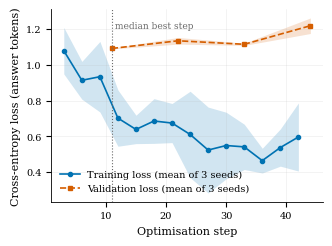

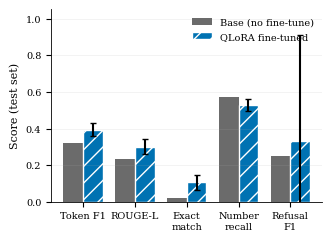

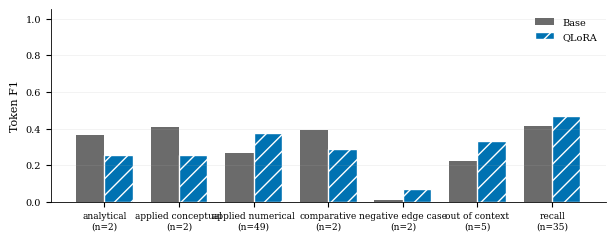

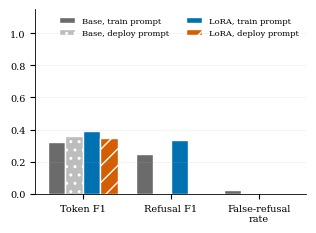

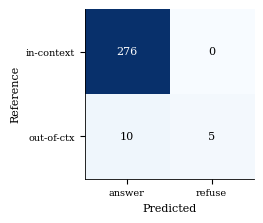

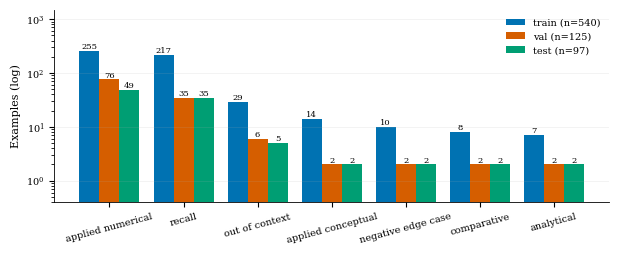

Figures saved to /content/drive/MyDrive/os_tutor_ft2/main/figures


In [18]:
import matplotlib; import matplotlib.pyplot as plt
BLUE, ORANGE, GREEN, GREY, RED, PURPLE = '#0072B2', '#D55E00', '#009E73', '#6b6b6b', '#CC3311', '#8c5cb5'
plt.rcParams.update({'font.family':'serif','font.size':8,'axes.labelsize':8,'legend.fontsize':7,'xtick.labelsize':7,'ytick.labelsize':7,
                     'axes.linewidth':0.6,'axes.spines.top':False,'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.25,
                     'grid.linewidth':0.4,'pdf.fonttype':42,'savefig.dpi':300,'savefig.bbox':'tight'})
COL_W, FULL_W = 3.5, 7.16
FIG = os.path.join(RUN_DIR, 'figures')
def savefig(fig, name):
    for ext in ('pdf', 'png'): fig.savefig(os.path.join(FIG, f'{name}.{ext}'))
    plt.show()

# Fig 1: loss curves, mean +- std over seeds
logs = {s: json.load(open(os.path.join(RUN_DIR, f'seed_{s}', 'log_history.json'))) for s in CFG['SEEDS']}
def series(log, key): return pd.Series({h['step']: h[key] for h in log if key in h})
fig, ax = plt.subplots(figsize=(COL_W, 2.5))
for key, col, mk, ls, lab in [('loss', BLUE, 'o', '-', 'Training loss'), ('eval_loss', ORANGE, 's', '--', 'Validation loss')]:
    df = pd.DataFrame({s: series(logs[s], key) for s in CFG['SEEDS']}).dropna(how='all').sort_index()
    m, sd = df.mean(1), df.std(1).fillna(0)
    ax.plot(m.index, m.values, color=col, marker=mk, ms=3, lw=1.2, ls=ls, label=lab + (f' (mean of {len(CFG["SEEDS"])} seeds)' if len(CFG['SEEDS'])>1 else ''))
    ax.fill_between(m.index, m - sd, m + sd, color=col, alpha=0.18, lw=0)
bs_ = [all_runs[s]['best_step'] for s in CFG['SEEDS']]
ax.axvline(np.median(bs_), color=GREY, lw=0.8, ls=':'); ax.text(np.median(bs_), ax.get_ylim()[1]*0.95, ' median best step', fontsize=6.5, color=GREY, va='top')
ax.set_xlabel('Optimisation step'); ax.set_ylabel('Cross-entropy loss' + (' (answer tokens)' if CFG['TRAIN_ON_RESPONSES_ONLY'] else ''))
ax.legend(frameon=False); savefig(fig, 'fig_loss_curves')

# Fig 2: base vs LoRA headline metrics with error bars
fig, ax = plt.subplots(figsize=(COL_W, 2.5))
names = ['F1', 'ROUGE_L', 'EM', 'NumRecall', 'Refusal_F1']; labs = ['Token F1', 'ROUGE-L', 'Exact\nmatch', 'Number\nrecall', 'Refusal\nF1']
seeds_m = pd.DataFrame([all_runs[s]['train_prompt'] for s in CFG['SEEDS']])
x = np.arange(len(names)); w = 0.38
ax.bar(x - w/2, [base_res['train_prompt'][n] for n in names], w, color=GREY, label='Base (no fine-tune)')
ax.bar(x + w/2, seeds_m[names].mean(), w, yerr=(seeds_m[names].std(ddof=1).fillna(0) if len(seeds_m) > 1 else None), capsize=2,
       color=BLUE, hatch='//', edgecolor='white', label='QLoRA fine-tuned')
ax.set_xticks(x); ax.set_xticklabels(labs); ax.set_ylim(0, 1.05); ax.set_ylabel('Score (test set)'); ax.legend(frameon=False, loc='upper right', ncol=1)
ax.grid(axis='x', visible=False); savefig(fig, 'fig_base_vs_lora')

# Fig 3: per-category F1
pc = percat.copy(); fig, ax = plt.subplots(figsize=(FULL_W, 2.5)); x = np.arange(len(pc)); w = 0.38
ax.bar(x - w/2, pc.base_F1, w, color=GREY, label='Base'); ax.bar(x + w/2, pc.LoRA_F1, w, color=BLUE, hatch='//', edgecolor='white', label='QLoRA')
ax.set_xticks(x); ax.set_xticklabels([f"{c.replace('_',' ')}\n(n={n})" for c, n in zip(pc.index, pc.n)], fontsize=6.5)
ax.set_ylim(0, 1.05); ax.set_ylabel('Token F1'); ax.legend(frameon=False); ax.grid(axis='x', visible=False); savefig(fig, 'fig_per_category_f1')

# Fig 4: train vs deployed system prompt (prompt-robustness)
if CFG['EVAL_DEPLOY_PROMPT']:
    fig, ax = plt.subplots(figsize=(COL_W, 2.4)); x = np.arange(3); w = 0.2
    nm = ['F1', 'Refusal_F1', 'FalseRefusal']
    def m(pr, who):
        if who == 'base': return [base_res[pr][n] for n in nm]
        d = pd.DataFrame([all_runs[s][pr] for s in CFG['SEEDS']]); return list(d[nm].mean())
    for i, (pr, who, col, hat, lab) in enumerate([('train_prompt','base',GREY,'','Base, train prompt'), ('deploy_prompt','base','#bdbdbd','..','Base, deploy prompt'),
                                                   ('train_prompt','lora',BLUE,'','LoRA, train prompt'), ('deploy_prompt','lora',ORANGE,'//','LoRA, deploy prompt')]):
        ax.bar(x + (i-1.5)*w, m(pr, who), w, color=col, hatch=hat, edgecolor='white', label=lab)
    ax.set_xticks(x); ax.set_xticklabels(['Token F1', 'Refusal F1', 'False-refusal\nrate']); ax.set_ylim(0, 1.15); ax.legend(frameon=False, fontsize=6, ncol=2)
    ax.grid(axis='x', visible=False); savefig(fig, 'fig_prompt_robustness')

# Fig 5: refusal confusion matrix (pooled over seeds, train prompt)
pool = pd.concat([load_preds(s, 'train_prompt') for s in CFG['SEEDS']])
cm = pd.crosstab(pool.ref_ooc, pool.pred_ooc).reindex(index=[False, True], columns=[False, True], fill_value=0)
fig, ax = plt.subplots(figsize=(2.4, 2.2)); ax.imshow(cm.values, cmap='Blues'); ax.grid(False)
for i in range(2):
    for j in range(2): ax.text(j, i, int(cm.values[i, j]), ha='center', va='center', color='white' if cm.values[i, j] > cm.values.max()/2 else 'black')
ax.set_xticks([0, 1]); ax.set_xticklabels(['answer', 'refuse']); ax.set_yticks([0, 1]); ax.set_yticklabels(['in-context', 'out-of-ctx'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Reference'); savefig(fig, 'fig_refusal_confusion')

# Fig 6: dataset composition after the group split
fig, ax = plt.subplots(figsize=(FULL_W, 2.5)); t2 = pd.crosstab(raw.category, raw.split).reindex(columns=['train','val','test']).fillna(0)
t2 = t2.loc[t2.sum(1).sort_values(ascending=False).index]; x = np.arange(len(t2)); w = 0.27
for i, (s, col) in enumerate([('train', BLUE), ('val', ORANGE), ('test', GREEN)]):
    ax.bar(x + (i-1)*w, t2[s].clip(lower=0.5), w, color=col, label=f'{s} (n={int(t2[s].sum())})')
    for xi, v in zip(x, t2[s]): ax.text(xi + (i-1)*w, max(v, .5)*1.1, int(v), ha='center', fontsize=6)
ax.set_yscale('log'); ax.set_ylim(0.4, 1500); ax.set_xticks(x); ax.set_xticklabels([c.replace('_', ' ') for c in t2.index], rotation=15)
ax.set_ylabel('Examples (log)'); ax.legend(frameon=False); ax.grid(axis='x', visible=False); savefig(fig, 'fig_dataset_split')
print('Figures saved to', FIG)

## 8 · Error analysis (qualitative table for the paper)

In [19]:
best_seed = min(CFG['SEEDS'], key=lambda s: all_runs[s]['answer_nll_val'])     # chosen on VALIDATION, never on test
print('Best seed (lowest validation answer-NLL):', best_seed)
bp = load_preds(best_seed, 'train_prompt')
bp['verdict'] = np.select([bp.ref_ooc & bp.pred_ooc, bp.ref_ooc & ~bp.pred_ooc, ~bp.ref_ooc & bp.pred_ooc],
                          ['correct refusal', 'MISSED refusal (hallucinated)', 'FALSE refusal'], default='answered')
print(bp.verdict.value_counts().to_string())
pd.set_option('display.max_colwidth', 160)
worst = bp[~bp.ref_ooc].sort_values('f1').head(5)[['category','question','completion','pred','f1']]
best  = bp[~bp.ref_ooc].sort_values('f1', ascending=False).head(3)[['category','question','completion','pred','f1']]
print('\n--- 5 lowest-F1 answers ---'); print(worst.to_string(index=False))
print('\n--- 3 highest-F1 answers ---'); print(best.to_string(index=False))
bp.to_csv(os.path.join(RUN_DIR, 'error_analysis_best_seed.csv'), index=False)

Best seed (lowest validation answer-NLL): 42
verdict
answered                         92
MISSED refusal (hallucinated)     5

--- 5 lowest-F1 answers ---
          category                                                                                                                                                                                            question                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                        

## 9 · Export: best adapter → merged fp16 model → sanity check → zip

In [20]:
best_adapter = os.path.join(RUN_DIR, f'seed_{best_seed}', 'adapter')
MERGE_DIR = os.path.join(RUN_DIR, 'merged_fp16')
if not os.path.exists(os.path.join(MERGE_DIR, 'config.json')):
    model, tok = FastLanguageModel.from_pretrained(model_name=best_adapter, max_seq_length=CFG['MAX_SEQ_LEN'], load_in_4bit=True, dtype=None)
    model.save_pretrained_merged(MERGE_DIR, tok, save_method='merged_16bit')
    free_gpu(model, tok)
print('Merged model:', MERGE_DIR)

# Sanity check: the merged fp16 model should score about the same as adapter+4bit on a test subset.
# (Not bit-identical: the adapter run uses a 4-bit base, the merged model is fp16.)
from transformers import AutoModelForCausalLM
sub = test_df.head(24)
mtok = AutoTokenizer.from_pretrained(MERGE_DIR)
mm = AutoModelForCausalLM.from_pretrained(MERGE_DIR, torch_dtype=torch.float16, device_map='cuda')
msc = score_predictions(sub, generate_answers(mm, mtok, sub))
ref = load_preds(best_seed, 'train_prompt').head(24)
print(f"Merged fp16  F1={msc.f1.mean():.3f} | adapter+4bit F1={ref.f1.mean():.3f} | identical outputs: {(msc.pred.values == ref.pred.values).mean():.0%}")
free_gpu(mm, mtok)

art = os.path.join(RUN_DIR, 'artifacts'); os.makedirs(art, exist_ok=True)
shutil.copytree(best_adapter, os.path.join(art, 'best_adapter'), dirs_exist_ok=True)
shutil.copytree(os.path.join(RUN_DIR, 'figures'), os.path.join(art, 'figures'), dirs_exist_ok=True)
for f in ['config.json', 'data_audit.json', 'per_category_f1.csv', 'error_analysis_best_seed.csv']:
    shutil.copy(os.path.join(RUN_DIR, f), art)
json.dump({'env': ENV, 'best_seed': best_seed, 'runs': all_runs, 'base': base_res}, open(os.path.join(art, 'results.json'), 'w'), indent=2, default=str)
zip_path = shutil.make_archive(os.path.join(WORK_DIR, f"os_tutor_ft2_{CFG['EXPERIMENT']}"), 'zip', art)
print('Artifacts zip:', zip_path)
if IN_COLAB:
    from google.colab import files; files.download(zip_path)

==((====))==  Unsloth 2026.10.10: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).


config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/os_tutor_ft2/main/merged_fp16/tokenizer_config.json.


...

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=400) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Merged fp16  F1=0.423 | adapter+4bit F1=0.431 | identical outputs: 21%
Artifacts zip: /content/drive/MyDrive/os_tutor_ft2/os_tutor_ft2_main.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [9]:
import os
import glob
from google.colab import files

# Dynamically lookup configuration variables from active state
try:
    active_work_dir = WORK_DIR
    active_experiment = CFG.get('EXPERIMENT', 'main')
except NameError:
    active_work_dir = '/content/drive/MyDrive/os_tutor_ft2'
    active_experiment = 'main'

search_paths = [
    os.path.join(active_work_dir, f'os_tutor_ft2_{active_experiment}.zip'),
    os.path.join(active_work_dir, '*.zip'),
    '/content/**/*.zip',
    './**/*.zip'
]

target_zip = None
for path_pattern in search_paths:
    matches = glob.glob(path_pattern, recursive=True)
    if matches:
        target_zip = matches[0]
        break

if target_zip and os.path.exists(target_zip):
    print(f'Downloading artifact zip found at: {target_zip}')
    files.download(target_zip)
else:
    print(f'Could not locate zip with search patterns: {search_paths}')
    print('Current Working Directory contents:', os.listdir('.'))
    if os.path.exists(active_work_dir):
        print(f'Contents of {active_work_dir}:', os.listdir(active_work_dir))

Could not locate zip with search patterns: ['/content/drive/MyDrive/os_tutor_ft2/os_tutor_ft2_main.zip', '/content/drive/MyDrive/os_tutor_ft2/*.zip', '/content/**/*.zip', './**/*.zip']
Current Working Directory contents: ['.config', 'sample_data']


## 10 · Inference demo (format must match training)

In [ ]:
model, tok = FastLanguageModel.from_pretrained(model_name=best_adapter, max_seq_length=CFG['MAX_SEQ_LEN'], load_in_4bit=True, dtype=None)
FastLanguageModel.for_inference(model)

def ask(context, question, system=SYSTEM_PROMPT):
    # EXACT user-turn format used in training: 'Textbook passages:\n<ctx>\n\nQuestion: <q>'
    user = f'Textbook passages:\n{context}\n\nQuestion: {question}'
    msgs = [{'role': 'system', 'content': system}, {'role': 'user', 'content': user}]
    tok.padding_side = 'left'
    enc = tok(tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True), return_tensors='pt').to('cuda')
    with torch.no_grad():
        out = model.generate(**enc, max_new_tokens=CFG['GEN_MAX_NEW_TOKENS'], do_sample=False, pad_token_id=tok.pad_token_id)
    return tok.decode(out[0, enc.input_ids.shape[1]:], skip_special_tokens=True).strip()

ctx = ('A deadlock is a situation where a set of processes are blocked because each process is holding a resource '
       'and waiting for another resource acquired by some other process.')
print('Q: What is a deadlock?\nA:', ask(ctx, 'What is a deadlock?'))
print('\nQ: What is the capital of France?  (expect OUT_OF_CONTEXT)\nA:', ask(ctx, 'What is the capital of France?'))
ex = test_df[~test_df.category.isin(['out_of_context'])].iloc[0]
print(f'\n[test example, {ex.category}]\nQ: {ex.question[:200]}\nA: {ask(ex.context, ex.question)[:500]}')
free_gpu(model, tok)

## 11 · Ablation study — compare experiments
To add a row: change `EXPERIMENT` and **one** switch in the Config cell, restart the runtime, *Run all*. Suggested set for the paper:

| `EXPERIMENT` | Change | Tests |
|---|---|---|
| `main` | defaults | full method |
| `abl_fullseq_loss` | `TRAIN_ON_RESPONSES_ONLY=False` | does answer-only loss matter? |
| `abl_oversample3` | `OVERSAMPLE_FACTOR=3` | v1's duplication strategy |
| `abl_grounded_only` | `FILTER_UNGROUNDED=True` | does cleaning ungrounded answers help? |
| `abl_r8` / `abl_r32` | `LORA_R` | rank sensitivity |

In [ ]:
rows = []
for exp in sorted(os.listdir(WORK_DIR)):
    d = os.path.join(WORK_DIR, exp)
    if not os.path.isdir(d) or not os.path.exists(os.path.join(d, 'config.json')): continue
    ms = [json.load(open(os.path.join(d, s, 'metrics.json'))) for s in sorted(os.listdir(d)) if s.startswith('seed_') and os.path.exists(os.path.join(d, s, 'metrics.json'))]
    if not ms: continue
    df = pd.DataFrame([{**m['train_prompt'], 'nll': m['answer_nll_test']} for m in ms])
    f = lambda c: f'{df[c].mean():.3f}' + (f' ± {df[c].std(ddof=1):.3f}' if len(df) > 1 else '')
    rows.append({'experiment': exp, 'seeds': len(ms), 'F1': f('F1'), 'ROUGE-L': f('ROUGE_L'), 'NumRecall': f('NumRecall'),
                 'Refusal F1': f('Refusal_F1'), 'False-refusal': f('FalseRefusal'), 'test NLL': f('nll')})
print(pd.DataFrame(rows).to_string(index=False) if rows else 'No finished experiments yet.')

## 12 · Reporting checklist (what this notebook does *not* do for you)
* **Add data for tiny categories.** `analytical`, `comparative`, `applied_conceptual`, `negative_edge_case` have 10–17 training rows in total; per-category numbers with n < 5 must be reported as anecdotal, not as results.
* **Refusal data is thin.** The 40 `out_of_context` rows use only 14 distinct off-topic questions (`ooc_unique_questions` in the audit), so refusal is learned from very little diversity; add many more distinct off-topic *and* near-topic-but-unanswerable questions.
* **Generated data caveat.** Passages are generic summaries re-used across many questions (124 unique passages for 762 rows). Say so in the paper and state that generalisation is to *unseen passages*, not unseen topics.
* **End-to-end RAG evaluation** (RAGAS faithfulness / relevancy over the *full* question set, not 5) lives in `eval/`; this notebook evaluates the generator in isolation with gold passages. Report both.
* **Human evaluation** (≥ 3 raters, ≥ 50 answers, κ) is still missing and is the most-requested item for education papers.
* **Deployment mismatch:** `rag/qwen_chain.py` defaults to a different system prompt than the one trained on; Fig. *prompt robustness* quantifies the cost. Either serve with the training prompt or retrain on the deploy prompt.
* Library versions are printed in §1 and saved to `results.json`; cite them.